<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula26a_linear_regression_with_include_bias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

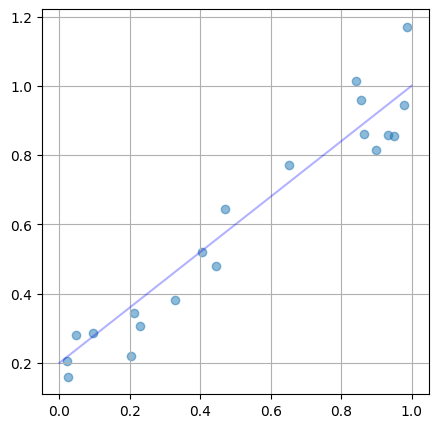

In [4]:
import numpy as np
from matplotlib import pyplot as plt

def create_regression_dataset(m=20, coefs=[1], intercept=-1):
  n = len(coefs)
  X = np.random.rand(m, n)
  noise = np.random.randn(m, n) * 0.1
  y = X * coefs + intercept + noise
  return X, y

def plot_dataset(X, y):
  plt.scatter(X[:,0], y, alpha=0.5)
  plt.grid(True)

def plot_line(coefs, intercept, color="green"):
  xs = np.array([0,1])
  ys = coefs * xs + intercept
  plt.plot(xs, ys, c=color, alpha=0.3)

coefs = [0.8]
intercept = 0.2
X, y = create_regression_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plt.show()

rmse: 0.08146018392651914
coefs: [0.84469176]		intercept: 0.16264908701149128


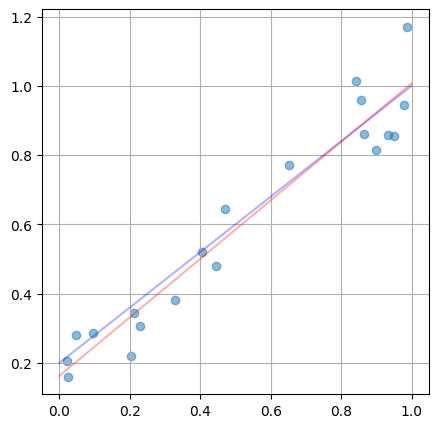

In [37]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import root_mean_squared_error

class LinearRegression(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=1000, learning_rate=0.05):
    self.max_iter = max_iter
    self.learning_rate = learning_rate

  def fit(self, X, y):
    y = y.reshape(-1)
    self.coefs = np.random.rand(X.shape[1])
    self.intercept = 0
    for _ in range(self.max_iter):
      y_pred = self.predict(X)
      error = y - y_pred
      self.coefs += X.T @ error * self.learning_rate / X.shape[0]
      self.intercept += error.sum() * self.learning_rate / X.shape[0]
    return self

  def predict(self, X):
    logits = X @ self.coefs + self.intercept
    y_pred = logits
    return y_pred


model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print(f"rmse: {root_mean_squared_error(y, y_pred)}")
print(f"coefs: {model.coefs}\t\tintercept: {model.intercept}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plot_line(model.coefs, model.intercept, color="red")
plt.show()

In [36]:
def include_bias(X):
  return np.c_[np.ones((X.shape[0],1)), X]

include_bias(X)

array([[1.        , 0.32873207],
       [1.        , 0.90028809],
       [1.        , 0.22815767],
       [1.        , 0.94873788],
       [1.        , 0.02053773],
       [1.        , 0.46972962],
       [1.        , 0.21289437],
       [1.        , 0.0243712 ],
       [1.        , 0.04596579],
       [1.        , 0.09451056],
       [1.        , 0.84158805],
       [1.        , 0.98725789],
       [1.        , 0.20259014],
       [1.        , 0.97955049],
       [1.        , 0.85740212],
       [1.        , 0.93273652],
       [1.        , 0.44576609],
       [1.        , 0.65152754],
       [1.        , 0.86606291],
       [1.        , 0.40461095]])

rmse: 0.0814596154183922
coefs: [0.84508344]		intercept: 0.1624226453343749


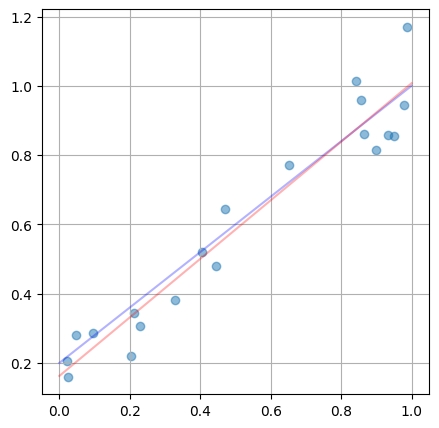

In [39]:
class LinearRegression(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=1000, learning_rate=0.05):
    self.max_iter = max_iter
    self.learning_rate = learning_rate

  def fit(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    self.w = np.random.rand(Xb.shape[1])
    for _ in range(self.max_iter):
      y_pred = self.predict(X)
      error = y - y_pred
      self.w += Xb.T @ error * self.learning_rate / Xb.shape[0]
    self.intercept = self.w[0]
    self.coefs = self.w[1:]
    return self

  def predict(self, X):
    Xb = include_bias(X)
    logits = Xb @ self.w
    y_pred = logits
    return y_pred


model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print(f"rmse: {root_mean_squared_error(y, y_pred)}")
print(f"coefs: {model.coefs}\t\tintercept: {model.intercept}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plot_line(model.coefs, model.intercept, color="red")
plt.show()

rmse: 0.08145920515058522
coefs: [0.84580266]		intercept: 0.16200683088519327


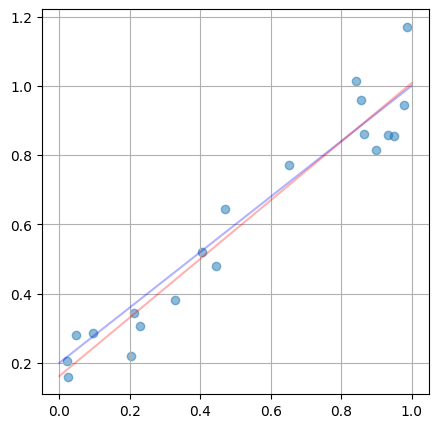

In [41]:
class LinearRegression(BaseEstimator, ClassifierMixin):
  def fit(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    self.w = np.linalg.pinv(Xb) @ y
    self.intercept = self.w[0]
    self.coefs = self.w[1:]
    return self

  def predict(self, X):
    Xb = include_bias(X)
    logits = Xb @ self.w
    y_pred = logits
    return y_pred


model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print(f"rmse: {root_mean_squared_error(y, y_pred)}")
print(f"coefs: {model.coefs}\t\tintercept: {model.intercept}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plot_line(model.coefs, model.intercept, color="red")
plt.show()

rmse: 0.08145920515058522
coefs: [0.84580266]		intercept: 0.16200683088519308


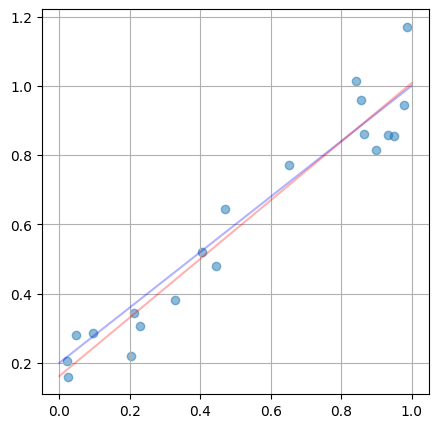

In [42]:
class LinearRegression(BaseEstimator, ClassifierMixin):
  def fit(self, X, y):
    y = y.reshape(-1)
    X_mean = X.mean(axis=0)
    y_mean = y.mean()
    X_c = X - X_mean
    y_c = y - y_mean
    self.coefs = np.linalg.pinv(X_c) @ y_c
    self.intercept = y_mean - self.coefs @ X_mean
    return self

  def predict(self, X):
    logits = X @ self.coefs + self.intercept
    y_pred = logits
    return y_pred


model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print(f"rmse: {root_mean_squared_error(y, y_pred)}")
print(f"coefs: {model.coefs}\t\tintercept: {model.intercept}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plot_line(model.coefs, model.intercept, color="red")
plt.show()